# DBSCAN / التجميع بالكثافة

Run the cells in order with **Shift + Enter**. Generate two crescents and add a few scattered points. DBSCAN sees only the coordinates, not the original labels.

شغّل الخلايا بالترتيب باستخدام **Shift + Enter**. ولّد هلالين وأضف نقاطًا متفرّقة. لا ترى الخوارزمية سوى الإحداثيات، دون التسميات الأصلية.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

moons, _ = make_moons(n_samples=240, noise=0.06, random_state=42)
rng = np.random.default_rng(42)
scattered = rng.uniform([-1.4, -0.9], [2.4, 1.4], size=(25, 2))
points = np.vstack([moons, scattered])

## Change the radius / غيّر نصف القطر

Keep the minimum number of points fixed at five. Try a smaller and a larger radius. Which one leaves the most points unassigned?

أبقِ الحد الأدنى للنقاط ثابتًا عند خمس نقاط. جرّب نصفَي قطر، أحدهما أصغر والآخر أكبر. أيّهما يترك أكبر عدد من النقاط بلا مجموعة؟

In [2]:
radii = [0.10, 0.18, 0.32]
models = [DBSCAN(eps=radius, min_samples=5).fit(points) for radius in radii]
for radius, model in zip(radii, models):
    clusters = set(model.labels_) - {-1}
    noise = np.count_nonzero(model.labels_ == -1)
    print(f'eps = {radius:.2f}: {len(clusters)} clusters, {noise} noise points')

eps = 0.10: 19 clusters, 41 noise points
eps = 0.18: 2 clusters, 11 noise points
eps = 0.32: 1 clusters, 6 noise points


## See it / شاهدها

Each color is a cluster. Filled dots are core points, rings are border points, and crosses are noise. Can you see where a large radius connects the crescents?

يمثّل كل لون مجموعة. الدوائر الممتلئة نقاط أساسية، والحلقات نقاط حدودية، والعلامات المتقاطعة ضوضاء. هل ترى أين يصل نصف القطر الكبير بين الهلالين؟

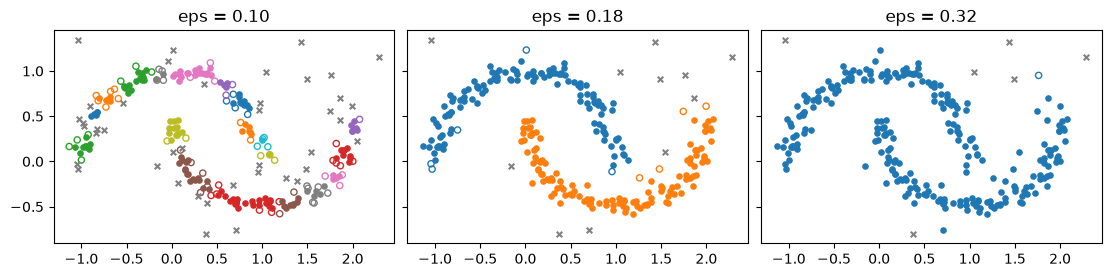

In [3]:
fig, axes = plt.subplots(1, len(radii), figsize=(11, 3.4), sharex=True, sharey=True, layout='constrained')
for ax, radius, model in zip(axes, radii, models):
    labels = model.labels_
    core = np.zeros(len(points), dtype=bool)
    core[model.core_sample_indices_] = True
    for label in sorted(set(labels) - {-1}):
        color = f'C{label % 10}'
        ax.scatter(*points[(labels == label) & core].T, color=color, s=14)
        ax.scatter(*points[(labels == label) & ~core].T, facecolors='none', edgecolors=color, s=20)
    ax.scatter(*points[labels == -1].T, color='grey', marker='x', s=16)
    ax.set(title=f'eps = {radius:.2f}', aspect='equal')
plt.show()